<a href="https://colab.research.google.com/github/Trendtek254/plp-da-a4-student-eda-and-board-report/blob/main/student_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
pd.set_option("display.max_columns", None)


In [18]:
students = pd.read_csv("student_performance.csv")

**Task 1**

***Grain and Dataset overview***

****Each row represents one student .The dataset contains 1,200 student records and 9 variables covering demographics,attendance,study hours and acdemic performance.****

In [21]:
print("Dataset shape:",students.shape)
print("\ncolumn names")
print(students.columns.tolist())
print("\nDataset information:")
students.info()
students.head()


#checking data quality.

print("Missing Values;")
print(students.isnull().sum())

print("\nDuplicated rows:")
print(students.duplicated().sum())

print("\nUnique Student IDs:")
print(students["student_id"].nunique())

print("\nAttendance Outside 0-1:")
print(((students["attendance_rate"]< 0) |
       (students["attendance_rate"]> 1)).sum())


print("\nNegative Study Hours:")
print((students["study_hours"] < 0).sum())


subjects = ["math","english","science"]
for subject in subjects:
  invalid = ((students[subject] < 0) |
             (students[subject] > 100)).sum()
  print(f"{subject}:{invalid} invalid scores")


Dataset shape: (1200, 9)

column names
['student_id', 'county', 'school_type', 'gender', 'attendance_rate', 'study_hours', 'math', 'english', 'science']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   student_id       1200 non-null   int64  
 1   county           1200 non-null   object 
 2   school_type      1200 non-null   object 
 3   gender           1200 non-null   object 
 4   attendance_rate  1200 non-null   float64
 5   study_hours      1200 non-null   float64
 6   math             1200 non-null   float64
 7   english          1200 non-null   float64
 8   science          1200 non-null   float64
dtypes: float64(5), int64(1), object(3)
memory usage: 84.5+ KB
Missing Values;
student_id         0
county             0
school_type        0
gender             0
attendance_rate    0
study_hours        0
math    

***### Structure Findings

- The dataset contains 1,200 student records and 9 original variables.
- Each row represents one student.
- There are no missing values or completely duplicated records.
- All 1,200 student IDs are unique.
- Attendance rates are within the valid range of 0 to 1.
- Study hours are non-negative.
- All subject scores are within the valid range of 0 to 100.
- The dataset contains numerical and categorical variables, with student_id treated as an identifier.

The dataset passed the initial data-quality checks, so no cleaning was required at this stage.***

***Task 2: Univariate Analysis***

****This section examines the distribution of numerical and categorical variables to understand their centre, spread, shape and frequency.****

In [28]:
#Numerical measurements or varuables
numerical_cols =[
    "attendance_rate",
    "study_hours",
    "math",
    "english",
    "science"
]


numerical_summary =  students[numerical_cols].describe().T
numerical_summary["skewness"] = students[numerical_cols].skew()
numerical_summary["kurtosis"] = students[numerical_cols].kurtosis()

numerical_summary


#categorical variables

categorical_cols = [
    "county",
    "school_type",
    "gender"
]

for col in categorical_cols:
  print("\nDistribution of", {col})

  counts = students[col].value_counts()

  shares = students[col].value_counts(normalize=True) * 100
  summary = pd.DataFrame({
      "Count":counts,
      "Share(%)":shares.round(2)

  })

  print(summary)

#Identifying study hours outliers
Q1 = students["study_hours"].quantile(0.25)
Q3 = students["study_hours"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR


outliers = students[
    (students["study_hours"] < lower_bound) |
    (students["study_hours"] > upper_bound)
  ]


print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)


print("Lower boundary:", lower_bound)
print("Upper boundary:", upper_bound)
print("Number of outliers:", len(outliers))
print("Ooutlier Percentage:", round(len(outliers)/len(students) * 100,2), "%")



Distribution of {'county'}
         Count  Share(%)
county                  
Mombasa    212     17.67
Kisumu     208     17.33
Nyeri      203     16.92
Nakuru     202     16.83
Turkana    191     15.92
Nairobi    184     15.33

Distribution of {'school_type'}
             Count  Share(%)
school_type                 
Public         866     72.17
Private        334     27.83

Distribution of {'gender'}
        Count  Share(%)
gender                 
F         612      51.0
M         588      49.0
Q1: 2.9
Q3: 6.7
IQR: 3.8000000000000003
Lower boundary: -2.8000000000000003
Upper boundary: 12.4
Number of outliers: 29
Ooutlier Percentage: 2.42 %


In [25]:
numerical_summary

,count,mean,std,min,25%,50%,75%,max,skewness,kurtosis
attendance_rate,1200.0,0.803650,0.119153,0.33,0.73,0.82,0.9,1.0,-0.857542,0.734899
study_hours,1200.0,5.077917,3.028098,0.20,2.90,4.50,6.7,23.3,1.173774,2.188994
math,1200.0,71.889167,10.858490,37.00,65.00,72.00,79.0,100.0,0.101623,-0.099440
english,1200.0,74.520833,10.486557,47.00,67.00,74.00,81.0,100.0,0.159639,-0.189420
science,1200.0,69.612500,12.022456,35.00,61.00,69.00,78.0,100.0,0.106528,-0.021837


****### Univariate Analysis Findings

- The average attendance rate was approximately 80.37%, with a median of 82%, suggesting generally high attendance among students.
- Students studied an average of 5.08 hours, while the median was 4.5 hours. Study hours were positively skewed, indicating that a smaller group of students studied considerably longer than most.
- English recorded the highest mean score (74.52), followed by Mathematics (71.89) and Science (69.61). Science also had the largest standard deviation (12.02), indicating greater variation in student performance.
- The three subject-score distributions were approximately symmetrical, with their means relatively close to their medians.
- Public-school students represented 72.17% of the dataset, compared with 27.83% from private schools. Gender distribution was nearly balanced, with females at 51% and males at 49%.
- The county distribution was relatively balanced, with Mombasa recording the highest number of students (212).
- The IQR method identified 29 study-hour outliers (2.42% of students). These observations were retained because unusually high study hours do not automatically indicate incorrect data.***

***Task3:***

In [32]:
students["average_score"] = students[
    ["math","english","science"]
].mean(axis=1)

students["performance_band"] = pd.cut(
    students["average_score"],
    bins=[-np.inf, 60, 75, np.inf],
    labels=["At Risk","Meeting","Exceeding"],
    right=False
)

students[[
    "math","english","science",
    "average_score","performance_band"
]].head(10)


,math,english,science,average_score,performance_band
0,81.0,71.0,73.0,75.000000,Exceeding
1,100.0,86.0,90.0,92.000000,Exceeding
2,82.0,89.0,90.0,87.000000,Exceeding
3,83.0,91.0,72.0,82.000000,Exceeding
4,76.0,69.0,62.0,69.000000,Meeting
5,75.0,93.0,95.0,87.666667,Exceeding
6,53.0,73.0,53.0,59.666667,At Risk
7,93.0,91.0,93.0,92.333333,Exceeding
8,68.0,77.0,57.0,67.333333,Meeting
9,71.0,73.0,74.0,72.666667,Meeting


In [33]:
students["performance_band"].value_counts()

,count
performance_band,
Meeting,672
Exceeding,429
At Risk,99


In [34]:
students["performance_band"].value_counts(normalize=True) * 100

,proportion
performance_band,
Meeting,56.00
Exceeding,35.75
At Risk,8.25


***### Performance Band Findings

The 1,200 students were classified into three performance bands based on their average Mathematics, English and Science scores.

- 672 students (56%) were in the Meeting category.
- 429 students (35.75%) were in the Exceeding category.
- 99 students (8.25%) were in the At Risk category.

The Meeting category represented the largest proportion of students. Although most students achieved an average score of at least 60, the 99 students classified as At Risk may require targeted academic support.***

***Task 4: Bivariate Analysis***

In [35]:
correlation_matrix = students[
    ["attendance_rate","study_hours",
     "math","english","science","average_score"]
].corr()
correlation_matrix.round(2)


,attendance_rate,study_hours,math,english,science,average_score
attendance_rate,1.00,-0.03,0.30,0.33,0.26,0.36
study_hours,-0.03,1.00,0.56,0.62,0.55,0.70
math,0.30,0.56,1.00,0.56,0.46,0.81
english,0.33,0.62,0.56,1.00,0.50,0.83
science,0.26,0.55,0.46,0.50,1.00,0.82
average_score,0.36,0.70,0.81,0.83,0.82,1.00


***### Bivariate Analysis: Correlation Findings

The correlation analysis identified several positive relationships with average academic performance.

- Study hours had a strong positive correlation with average score (r = 0.70), suggesting that students who reported more study hours generally achieved higher average scores.
- Attendance rate had a moderate positive correlation with average score (r = 0.36), indicating that higher attendance was associated with better academic performance.
- English, Science and Mathematics had correlations of 0.83, 0.82 and 0.81 with average score, respectively. These strong relationships are expected because average score is calculated using the three subject scores.
- Attendance rate and study hours had a very weak negative correlation (r = -0.03), suggesting almost no linear relationship between the two variables.

These findings describe associations and do not establish that one factor directly causes better academic performance.***

***Task 5:Comparing average scores by gender,school type and county.***

In [41]:
#students.groupby("gender")["average_score"].mean()

#students.groupby("school_type")["average_score"].mean()

students.groupby("county")["average_score"].mean().sort_values(ascending=False)


,average_score
county,
Kisumu,73.067308
Mombasa,72.169811
Nairobi,71.958333
Nyeri,71.939245
Nakuru,71.836634
Turkana,70.973822


In [42]:
risk_by_county = pd.crosstab(
    students["county"],
    students["performance_band"],
    normalize="index"
) * 100
risk_by_county.round(2)


performance_band,At Risk,Meeting,Exceeding
county,,,
Kisumu,8.17,50.48,41.35
Mombasa,8.96,54.25,36.79
Nairobi,9.24,55.43,35.33
Nakuru,6.44,61.88,31.68
Nyeri,8.87,54.68,36.45
Turkana,7.85,59.69,32.46


***### Bivariate Analysis: Correlation Findings

The correlation analysis identified several positive relationships with average academic performance.

- Study hours had a strong positive correlation with average score (r = 0.70), suggesting that students who reported more study hours generally achieved higher average scores.
- Attendance rate had a moderate positive correlation with average score (r = 0.36), indicating that higher attendance was associated with better academic performance.
- English, Science and Mathematics had correlations of 0.83, 0.82 and 0.81 with average score, respectively. These strong relationships are expected because average score is calculated using the three subject scores.
- Attendance rate and study hours had a very weak negative correlation (r = -0.03), suggesting almost no linear relationship between the two variables.

These findings describe associations and do not establish that one factor directly causes better academic performance.

**Gender comparison:** Female students recorded an average score of 72.10, while male students recorded 71.91. The difference was approximately 0.18 points, indicating very similar average academic performance between the two groups.


**School-type comparison:** Private-school students recorded an average score of 76.01, compared with 70.46 among public-school students. This represents an average difference of approximately 5.55 points in favour of private schools. The finding indicates a performance gap in the dataset, but it does not establish that school type directly causes the difference.


**County comparison:** Kisumu recorded the highest average student score at 73.07, while Turkana recorded the lowest at 70.97. The difference was approximately 2.09 points. Overall, average performance across the six counties was relatively similar.

**At Risk distribution by county:** Nairobi recorded the highest percentage of At Risk students at 9.24%, followed by Mombasa at 8.96%. Nakuru had the lowest At Risk percentage at 6.44%. Kisumu recorded the highest percentage of Exceeding students at 41.35%. These results show that county-level academic performance differs depending on the performance measure used.








***

***Task 6: Mulitivariate Analysis***


In [43]:
students["attendance_band"] = pd.cut(
    students["attendance_rate"],
    bins=[-np.inf, 0.75, 0.90, np.inf],
    labels=["Low", "Medium", "High"],
    right=False
)

students["attendance_band"].value_counts()

,count
attendance_band,
Medium,572
Low,327
High,301


In [45]:
attendance_pivot = students.pivot_table(
    values = "average_score",
    index = "attendance_band",
    columns = "school_type",
    aggfunc = "mean",
    observed = False
)
attendance_pivot.round(2)

school_type,Private,Public
attendance_band,,
Low,72.00,66.11
Medium,76.57,71.02
High,79.41,74.10


***### Multivariate Analysis: School Type and Attendance

The pivot table compared average student scores between public and private schools across three attendance bands.

Private-school students recorded higher average scores in every attendance group:

- Low attendance: Private 72.00, Public 66.11 (gap: 5.89 points).
- Medium attendance: Private 76.57, Public 71.02 (gap: 5.55 points).
- High attendance: Private 79.41, Public 74.10 (gap: 5.31 points).

The performance gap remained across all attendance groups, although it became slightly smaller at higher attendance levels. This suggests that attendance differences alone do not explain the observed school-type gap. Other factors may contribute to the difference.***

In [47]:
students["study_quartile"] = pd.qcut(
    students["study_hours"],
    q=4,
    labels=["Q1","Q2","Q3","Q4"]
)
students["study_quartile"].value_counts().sort_index()

,count
study_quartile,
Q1,311
Q2,302
Q3,288
Q4,299


In [49]:
study_pivot = students.pivot_table(
    values="average_score",
    index="study_quartile",
    columns="school_type",
    aggfunc="mean"
)

study_pivot.round(2)

/tmp/ipykernel_634/2304197876.py:1: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  study_pivot = students.pivot_table(


school_type,Private,Public
study_quartile,,
Q1,69.51,63.82
Q2,74.92,67.12
Q3,76.18,71.18
Q4,83.65,80.06


***### Study Hours, School Type and Academic Performance

- Average scores increase across study-hour quartiles for both public and private school students.
- Private school students have higher average scores than public school students in all four quartiles.
- The largest performance gap occurs in Q2 (7.80 points), while the smallest occurs in Q4 (3.59 points).
- Students in the highest study-hour quartile (Q4) have the highest average scores in both school types.

**Interpretation:** Study hours are positively associated with academic performance. However, differences between school types remain even when students are grouped by study hours.

**Limitation:** These comparisons show associations, not proof that studying more or attending a private school directly causes higher scores. Other factors may influence academic performance.***

***Task 7:Trends***

In [54]:
x = students["study_hours"].to_numpy()
y = students["average_score"].to_numpy()

slope, intercept = np.polyfit(x,y,1)

print("Slope:", slope)
print("Intercept:", intercept)



predicted = slope * x + intercept

ss_res = np.sum((y - predicted) ** 2)
ss_tot = np.sum((y - y.mean()) ** 2)
r_squared = 1 - (ss_res / ss_tot)
print("R-squared:",round(r_squared,3))


Slope: 2.1166077811501904
Intercept: 61.25954207130112
R-squared: 0.495


***### Linear Trend Analysis: Study Hours vs Average Score

A simple linear regression model was developed to examine the relationship between study hours and average academic performance.

**Regression equation:**

Average Score = 2.1166 × Study Hours + 61.2595

**Key findings:**

- The positive slope of 2.1166 indicates that each additional study hour is associated with an estimated 2.12-point increase in average score.
- The intercept is 61.2595, representing the model's predicted score when study hours are zero.
- The R² value of 0.495 indicates that study hours explain approximately 49.5% of the variation in average scores through this linear model.

**Limitations:**

The model shows an association, not causation. Other factors may influence academic performance. The model also assumes a linear relationship, which may not fully represent how studying affects every student.***

***Task 8:Producing charts.
***

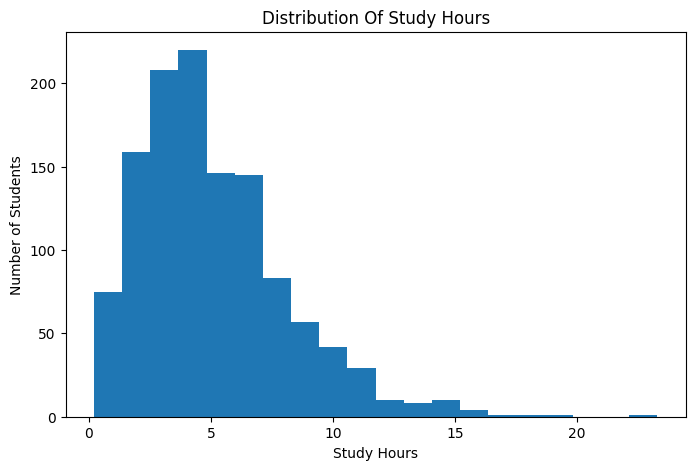

In [59]:
import os
os.makedirs("figures", exist_ok=True)

students["study_hours"].plot(
    kind="hist",
    bins=20,
    figsize=(8, 5),
    title="Distribution Of Study Hours",
    xlabel="Study Hours",
    ylabel="Number of Students"
)
plt.savefig("figures/study_hours_histogram.png")
plt.show()


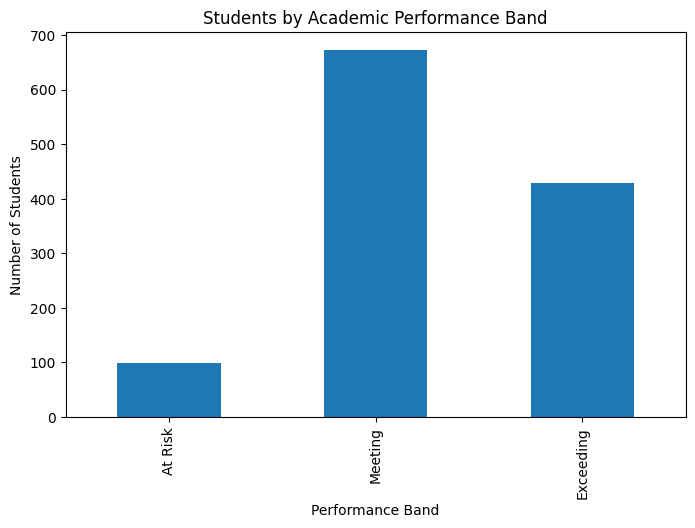

In [60]:
students["performance_band"].value_counts().reindex(
    ["At Risk", "Meeting", "Exceeding"]
).plot(
    kind="bar",
    figsize=(8, 5),
    title="Students by Academic Performance Band",
    xlabel="Performance Band",
    ylabel="Number of Students"
)

plt.savefig("figures/performance_bands_bar.png")
plt.show()

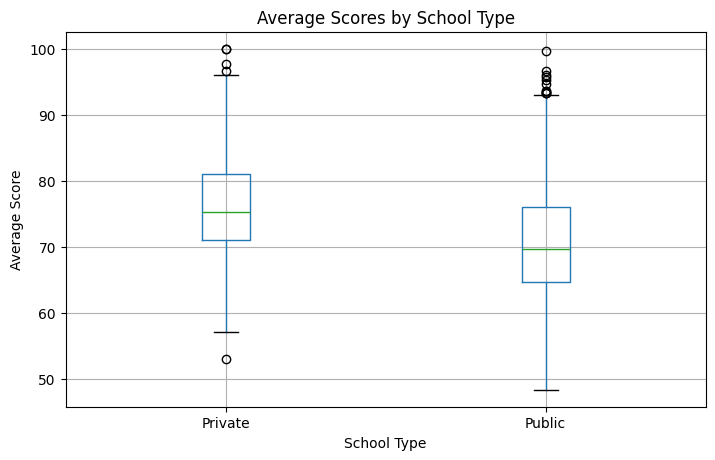

In [62]:
students.boxplot(
    column="average_score",
    by="school_type",
    figsize=(8, 5)
)

plt.title("Average Scores by School Type")
plt.suptitle("")
plt.xlabel("School Type")
plt.ylabel("Average Score")

plt.savefig("figures/average_score_boxplot.png")
plt.show()

***Task 9:5 key findings***


****## Findings

**1. Study hours are strongly associated with academic performance.**

Study hours have a strong positive correlation of 0.70 with average scores. Students in the highest study-hour quartile (Q4) achieved higher average scores than those in the lowest quartile (Q1). The regression model also showed an estimated increase of approximately 2.12 score points for each additional study hour.

**2. Attendance is positively associated with academic performance.**

Attendance has a moderate positive correlation of 0.36 with average scores. This suggests that students with higher attendance rates generally tend to achieve better academic results.

**3. Most students are meeting the expected performance level.**

Of the 1,200 students, 672 (56%) were in the Meeting category, 429 (35.75%) were Exceeding expectations, and 99 (8.25%) were At Risk. This indicates that most students are meeting or exceeding the expected performance level, although some still need additional support.

**4. Private school students have higher average scores than public school students.**

Private school students achieved an average score of 76.01, compared with 70.46 among public school students. The difference was approximately 5.55 points. Private school students also had higher average scores across all study-hour quartiles.

**5. Academic performance differs across counties.**

Kisumu recorded the highest average score at 73.07, while Turkana recorded the lowest at 70.97. Nairobi had the highest proportion of At Risk students at 9.24%, while Nakuru had the lowest at 6.44%.

## Recommendations

**1. Prioritise academic support for At Risk students.**

Introduce targeted tutoring, additional learning sessions and regular academic progress monitoring for students in the At Risk category. Use attendance and study-hour patterns to help identify students who may benefit from early intervention.

**2. Strengthen learning support in public schools and lower-performing groups.**

Prioritise additional learning resources, teacher support and structured study programmes in public schools. Monitor county-level performance to identify areas that may need additional programme support.

## Limitations

This analysis uses a generated dataset of 1,200 student records rather than verified real-world student records. Therefore, the findings may not represent actual student populations. Correlation and regression results show associations rather than causation, meaning that increased study hours or attendance cannot automatically be assumed to cause higher scores. Other factors, such as teaching quality, learning resources and individual circumstances, were not fully examined. Performance bands also depend on the selected score thresholds.****

